In [4]:
import os
import cv2
import matplotlib.pyplot as plt
import random
from PIL import Image
import torch
import torchvision.transforms as transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader
import torchvision.models as models
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

In [5]:
# folder paths
dataset_path = r'C:/Users/Owner/Documents/Lagoon_Public_Art_V26B/Photos/Artifact_Classification'

# training directory
train_dir = os.path.join(dataset_path, 'Train')

# file names
classes = os.listdir(train_dir)

In [21]:
transform = transforms.Compose([
	transforms.Resize((224,224)),
	transforms.ToTensor(),
	# transforms.Normalize([0.485,0.465,0.406],
	# 	[0.229,0.224,0.225])
])

In [22]:
train_dataset = ImageFolder(os.path.join(dataset_path, 'Train'), transform = transform)
val_dataset = ImageFolder(os.path.join(dataset_path, 'Val'), transform = transform)
test_dataset = ImageFolder(os.path.join(dataset_path, 'Test'), transform = transform)

train_loader = DataLoader(train_dataset, batch_size = 16, shuffle = True, num_workers = 0)
val_loader = DataLoader(val_dataset, batch_size = 8, shuffle = False)
test_loader = DataLoader(test_dataset, batch_size = 8, shuffle = False)

In [23]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu') # works with nvidia gpus

model = models.resnet18(pretrained = True)

for param in model.parameters():
	param.requires_grad = False

num_classes = len(train_dataset.classes)
model.fc = nn.Linear(model.fc.in_features, num_classes)

model = model.to(device)

optimizer = optim.Adam(model.parameters(), lr = 0.001)
criterion = nn.CrossEntropyLoss()

In [24]:
def train_one_epoch(model, loader):
	model.train()
	running_loss = 0

	for images, labels in loader:
		images, labels = images.to(device), labels.to(device)
		optimizer.zero_grad()
		outputs = model(images)
		loss = criterion(outputs, labels)
		loss.backward()
		optimizer.step()
		running_loss += loss.item()

	return running_loss / len(loader)

In [25]:
def evaluate(model, loader): 
	model.eval()
	correct = 0
	total = 0

	with torch.no_grad():
		for images, labels in loader:
			images, labels = images.to(device), labels.to(device)
			outputs = model(images)
			_, predicted = torch.max(outputs.data, 1)
			total += labels.size(0)
			correct += (predicted == labels).sum().item()

	return correct / total

In [ ]:
epochs = 120
for epoch in range(epochs):
	train_loss = train_one_epoch(model, train_loader)
	val_acc = evaluate(model, val_loader)
	print(f"Epoch {epoch + 1}, Train Loss: {train_loss:.4f}, Validation Accuracy: {val_acc:.4f}")

In [ ]:
test_acc = evaluate(model, test_loader)
print(f"Test Accuracy: {test_acc:.4f}")

In [14]:
def visualize_predictions(model, loader, n=5):
    model.eval
    images_shown = 0
    class_names = train_dataset.classes

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            outputs = model(images)
            _, preds = torch.max(outputs, 1)

            for i in range(n):
                img = images[i].cpu().permute(1,2,0).numpy()
                plt.imshow((img))
                plt.title(f'True: {class_names[labels[i]]}, Pred: {class_names[preds[i]]}')
                plt.axis('off')
                plt.show()

                images_shown += 1

                if images_shown >= n:
                    return

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.1007793..0.6220567].


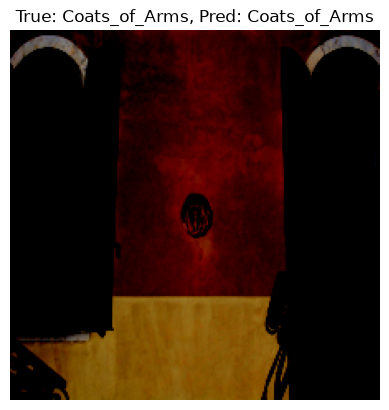

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..0.46793392].


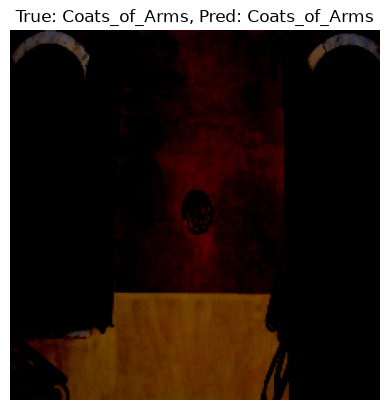

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.1007793..0.5193082].


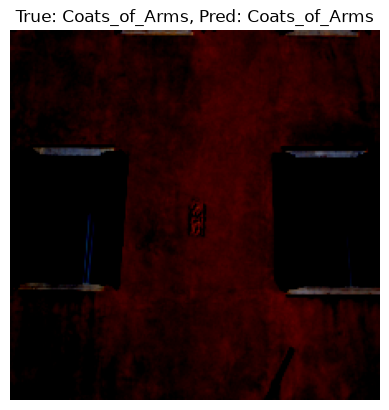

In [20]:
visualize_predictions(model, test_loader, 3)

In [16]:
import joblib

In [17]:
model_data = {
    'model_state_dict' : model.state_dict(),
    'class_to_idx': train_dataset.class_to_idx
}

In [ ]:
# joblib.dump(model_data, 'artifact_classifier_model.pkl')

['artifact_classifier_model.pkl']